**Прогнозирование с использованием ML**

В данном блокноте мы переработаем исходную поставленную ранее задачу по прогнозированию доходности в экстремальных условиях. Мы столкнулись с проблемой, когда пытались построить портфель ценных бумаг на основе прогнозов (лонг/шорт), хотя метрики показывали неплохие результаты для градиентного бустинга. Здесь мы попробуем подойти к проблеме прогнозирования с другой стороны - нашей целью будет исследование, какие методы машинного обучения лучше работают на ряде признаков, используемых в прогнозировании. В основном это будут технические признаки. Чтобы не лезть слишком далеко, мы не будем формировать портфель, а ограничимся лишь корректными прогнозами на основе временных рядов. Также планируется применить методы снижения размерности для выделения наиболее информативных признаков. Было бы неплохо также добавить в ислледования анализ новостей и социальных сетей с помощью нейронных сетей, но это пока в перспективе.

Итак, вновь начнём с загрузки временного ряда (свечей) с сайта Московской биржи - вновь выбираем наиболее ликвидные бумаги (SBER, GAZP, LKOH, NVTK, MGNT), которые имеют высокий вес в MOEX и которые не имеют ввиду высокой ликвидности широких спредов. Кроме того, для этих эмитентов имеется широкий диапазон торговли, что очень благоприятно для анализа. Однако, 5 эмитентов - мало, сигнал будет сильно зашумлен. Поэтому нам нужно добавить в анализ дополнительный набор бумаг, чтобы их было порядка 20. С этой целью критерием отбора будут бумаги с дневным оборотом > 100-200 млн рублей и спредом < 10 bps. К таким можно отнести голубые фишки: SBER, GAZP, LKOH, NVTK, MGNT, ROSN, TATN, GMKN, PLZL, VTBR, MOEX, SNGS, SNGSP, SBERP, а также бумаги второго эшелона: IRAO, TRNFP, PHOR, AFLT, MAGN, BSPB. На основе этого набора загрузим данные по ценам с сайта Московской биржи.

In [2]:
import pandas as pd
import requests
import time
import os

# даты конца/начала рядов
date_start = '2015-01-01'
date_end = '2024-12-31'
# тикеры
tickers = [
    'SBER', 'GAZP', 'LKOH', 'NVTK', 'MGNT', 'ROSN', 'TATN', 'GMKN', 'PLZL',
    'VTBR', 'MOEX', 'SNGS', 'SNGSP', 'SBERP',
    # второй эшелон
    'IRAO', 'TRNFP', 'PHOR', 'AFLT', 'MAGN', 'BSPB'
]

# функция, выполняющая загрузку конкретного тикера
def load_data(ticker, start=date_start, end=date_end):
  url = f'https://iss.moex.com/iss/engines/stock/markets/shares/securities/{ticker}/candles.json'
  all_data = []
  columns = None
  start_page = 0

  while True:
    # параметры для requests.get
    params = {
        'from': start,
        'till': end,
        'interval': 24,
        'start': start_page
    }

    try:
      r = requests.get(url, params=params, timeout=30)
      r.raise_for_status()
      j = r.json()
    except Exception as e:
      print(f'{ticker}: ошибка при загрузке на странице {start_page}: {e}')
      break

    candles = j.get('candles', {})
    if columns is None:
      columns = candles.get('columns', [])
    data = candles.get('data', [])
    if not data:
      break  # данные кончились

    all_data.extend(data) # добавляем то, что загрузили
    print(f'{ticker}: страница {start_page // 500 + 1}, всего {len(all_data)} свечей, последняя {data[-1][6]}')
    start_page += len(data)
    time.sleep(0.1)

  if not all_data:
    print(f'{ticker}: данные не загружены')
    return None

  df = pd.DataFrame(all_data, columns=columns)
  df['begin'] = pd.to_datetime(df['begin'])
  df = df.set_index('begin')
  df.index.name = 'datetime'

  return df[['open', 'high', 'low', 'close', 'volume']]  # свечи

os.makedirs('data/raw', exist_ok=True)

# загружаем тикеров
dfs = {}
for ticker in tickers:
  print(f'\n {ticker}')
  df = load_data(ticker, start=date_start, end=date_end)
  if df is not None:
    dfs[ticker] = df
    print(f'  - Загружено {df.shape} с {df.index.min().date()} по {df.index.max().date()}')

# собираем в набор: дата - тикер: данные
combined = pd.concat(dfs, axis=1)
combined.columns.names = ['ticker', 'field']
combined.index.name = 'datetime'
combined.to_parquet('data/raw/prices_moex_stable.parquet')


 SBER
SBER: страница 1, всего 500 свечей, последняя 2016-12-28 00:00:00
SBER: страница 2, всего 1000 свечей, последняя 2018-12-19 00:00:00
SBER: страница 3, всего 1500 свечей, последняя 2020-12-16 00:00:00
SBER: страница 4, всего 2000 свечей, последняя 2023-01-03 00:00:00
SBER: страница 5, всего 2500 свечей, последняя 2024-12-18 00:00:00
SBER: страница 6, всего 2509 свечей, последняя 2024-12-30 00:00:00
  - Загружено (2509, 5) с 2015-01-05 по 2024-12-30

 GAZP
GAZP: страница 1, всего 500 свечей, последняя 2016-12-28 00:00:00
GAZP: страница 2, всего 1000 свечей, последняя 2018-12-19 00:00:00
GAZP: страница 3, всего 1500 свечей, последняя 2020-12-16 00:00:00
GAZP: страница 4, всего 2000 свечей, последняя 2023-01-03 00:00:00
GAZP: страница 5, всего 2500 свечей, последняя 2024-12-18 00:00:00
GAZP: страница 6, всего 2509 свечей, последняя 2024-12-30 00:00:00
  - Загружено (2509, 5) с 2015-01-05 по 2024-12-30

 LKOH
LKOH: страница 1, всего 500 свечей, последняя 2016-12-28 00:00:00
LKOH: стр

С загрузкой сложностей не возникло. Теперь было бы неплохо визуализировать данные, с которыми мы работаем. Сделаем это при помощи программы ниже.

Можно использовать японские свечи, но на таком временном периоде масштаб будет слишком мелким. Поэтому ограничимся ценами закрытия и скользящими средними. Цены закрытия смотрим не случайно - ребалансировка портфеля осуществляется на основании данных за конец дня. Но в целом, здесь для визуализации можно было использовать и другие цены.

Тикеры: ['SBER', 'GAZP', 'LKOH', 'NVTK', 'MGNT', 'ROSN', 'TATN', 'GMKN', 'PLZL', 'VTBR', 'MOEX', 'SNGS', 'SNGSP', 'SBERP', 'IRAO', 'TRNFP', 'PHOR', 'AFLT', 'MAGN']


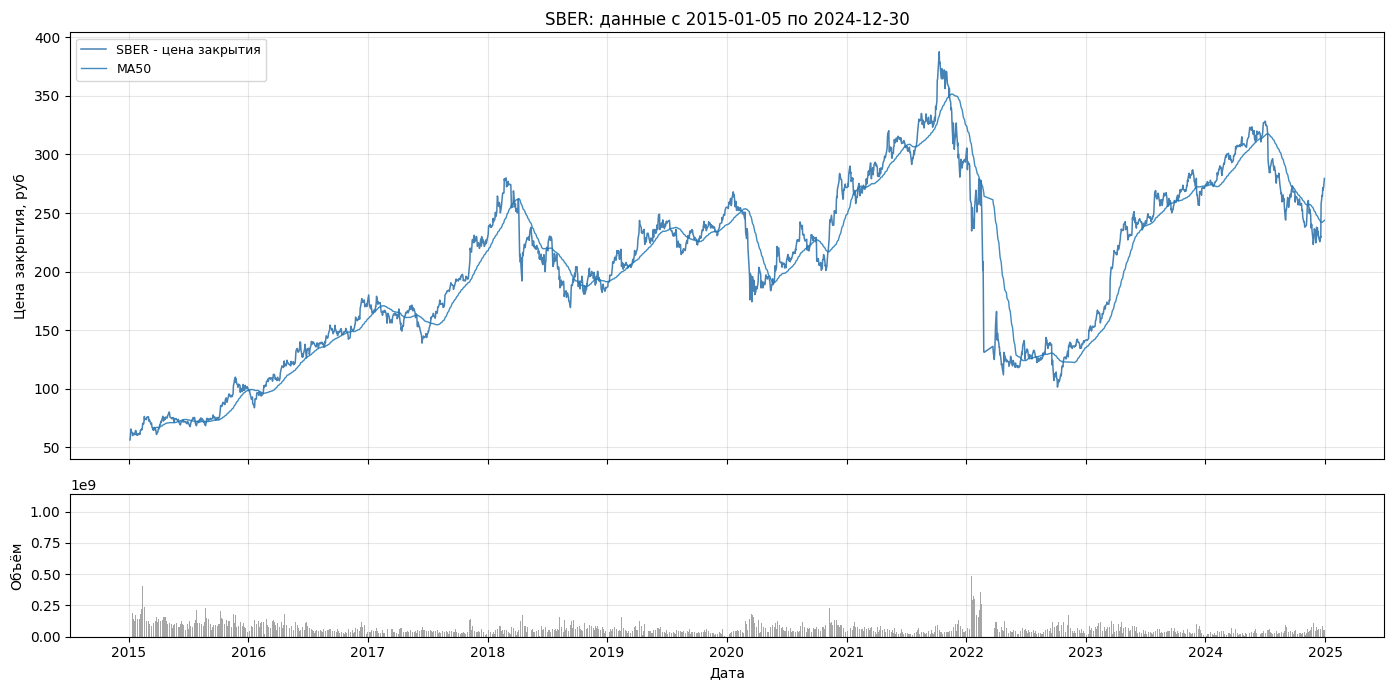

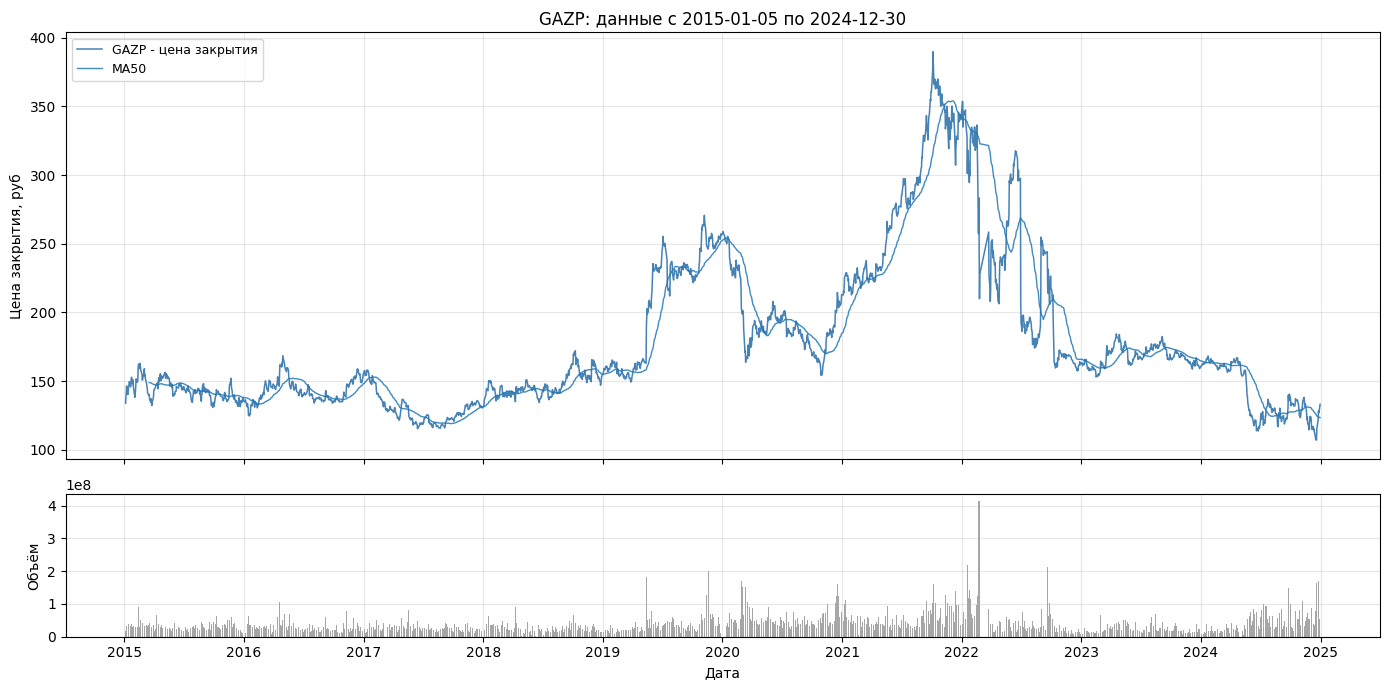

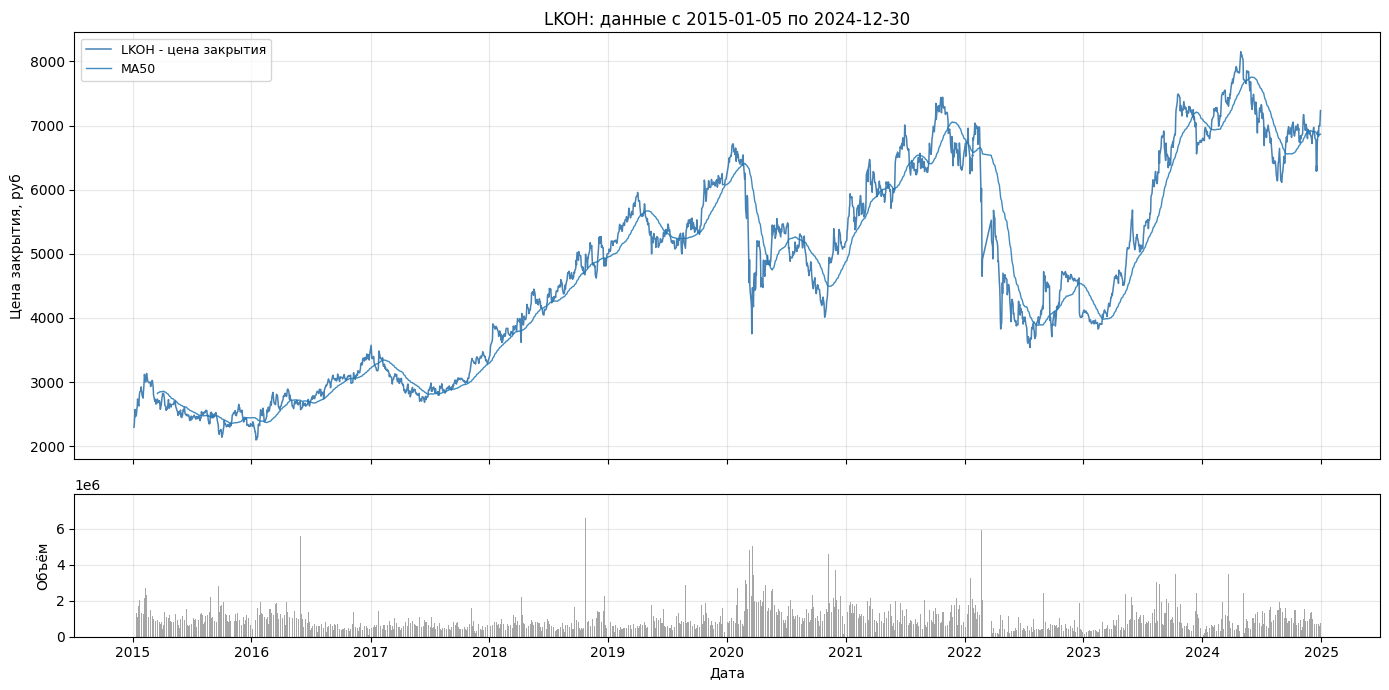

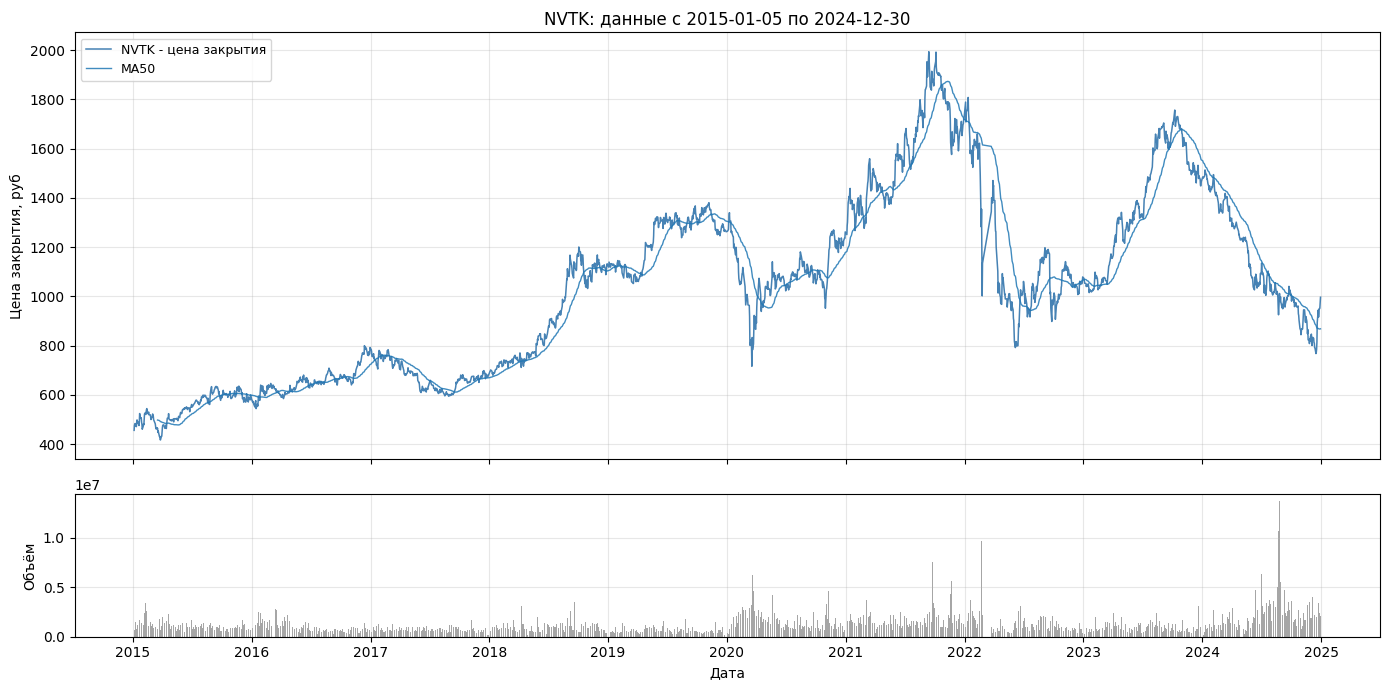

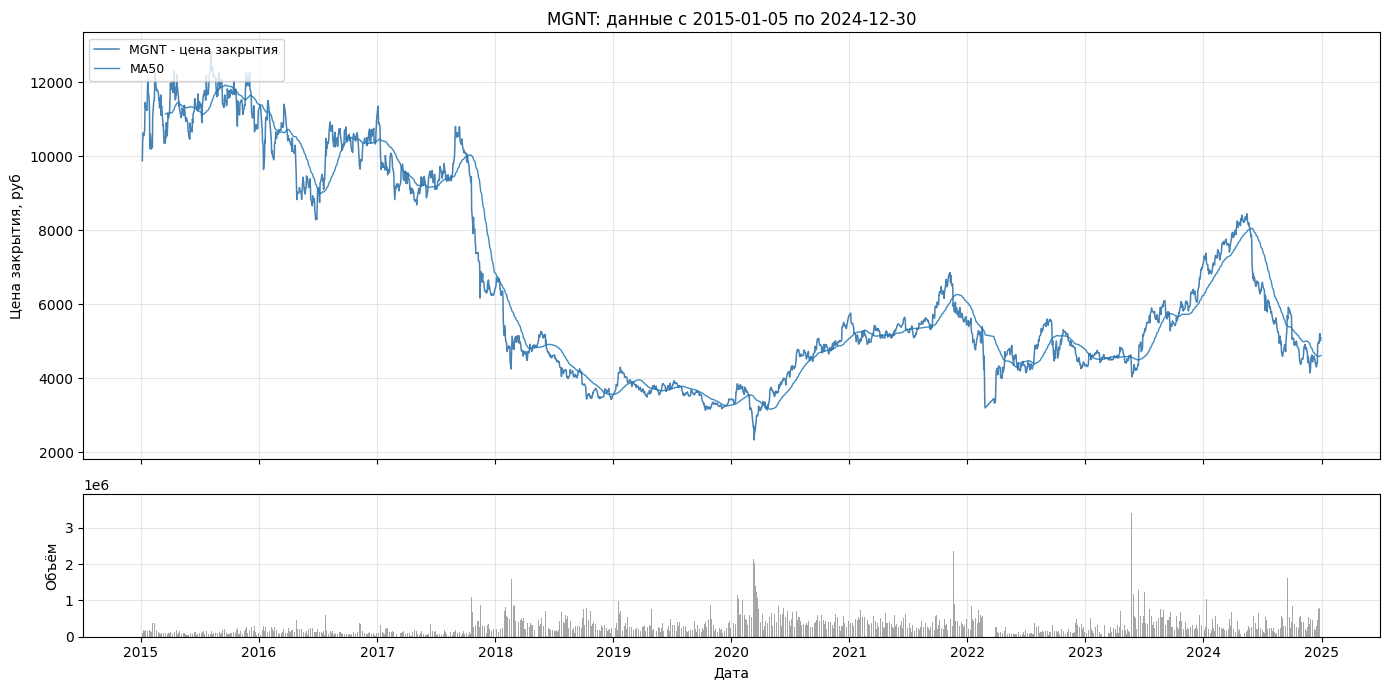

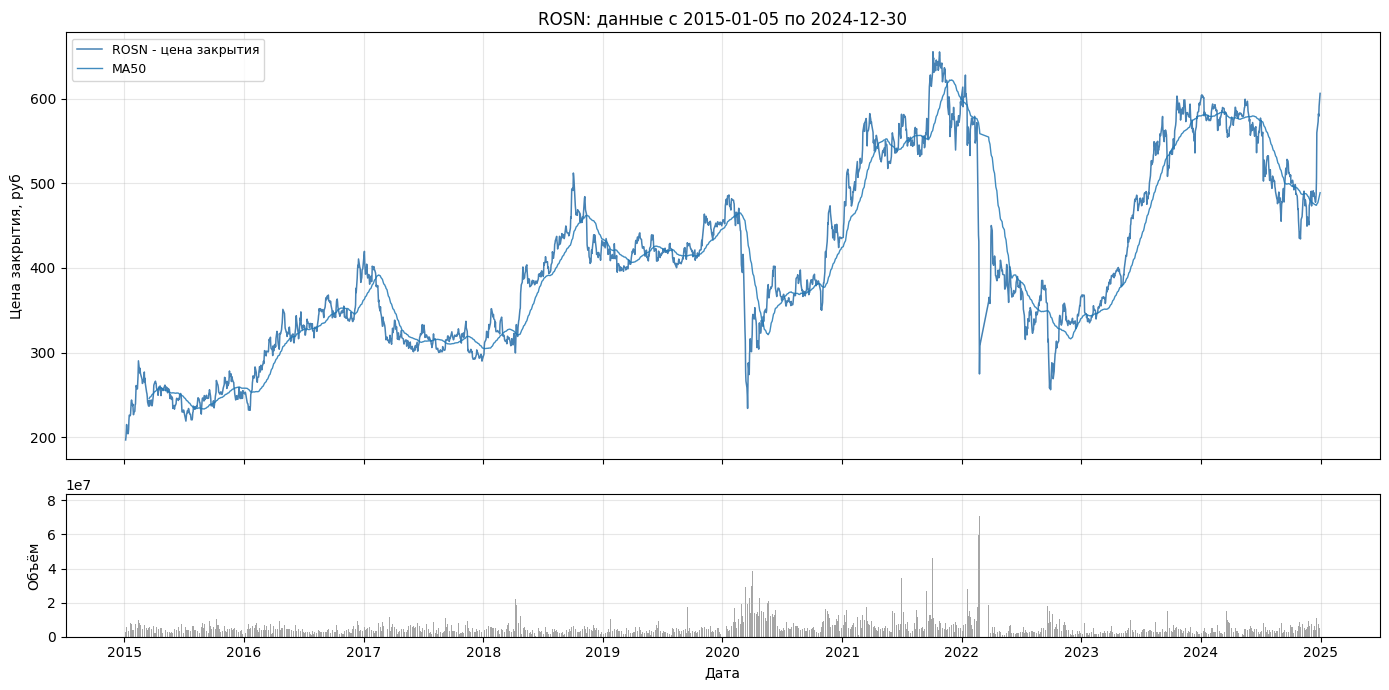

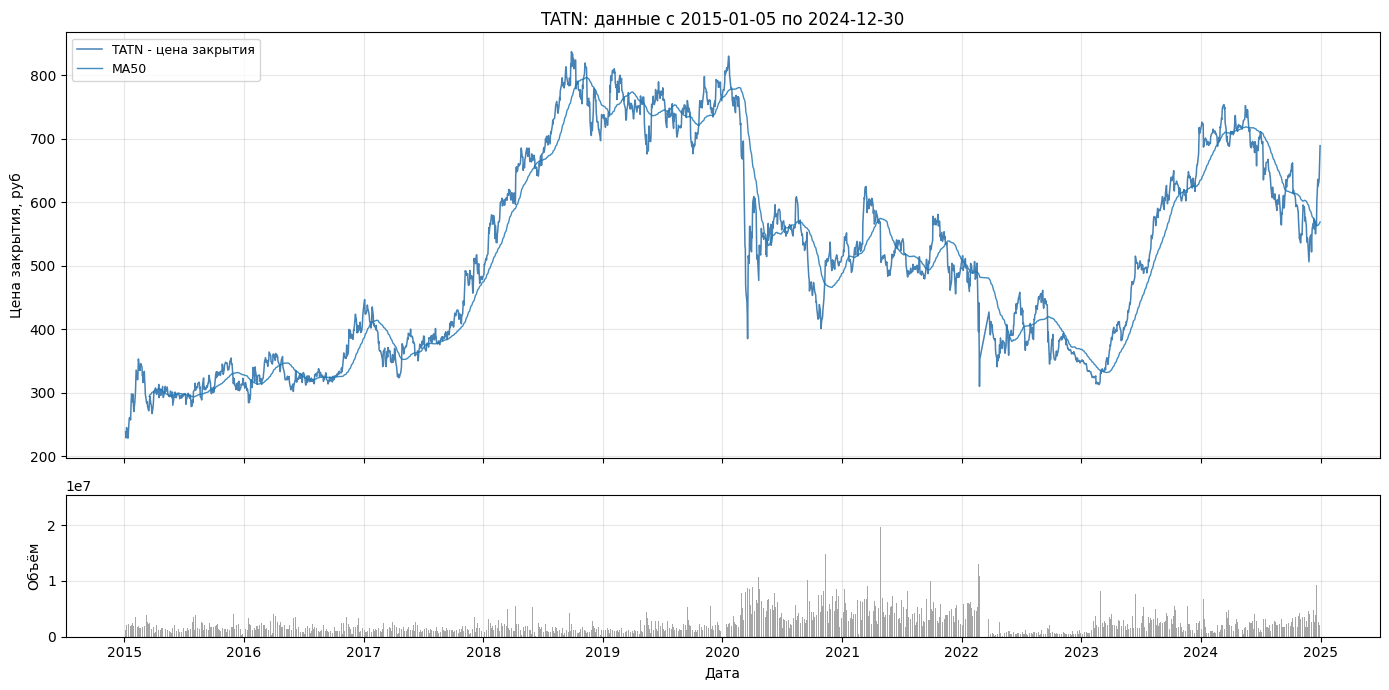

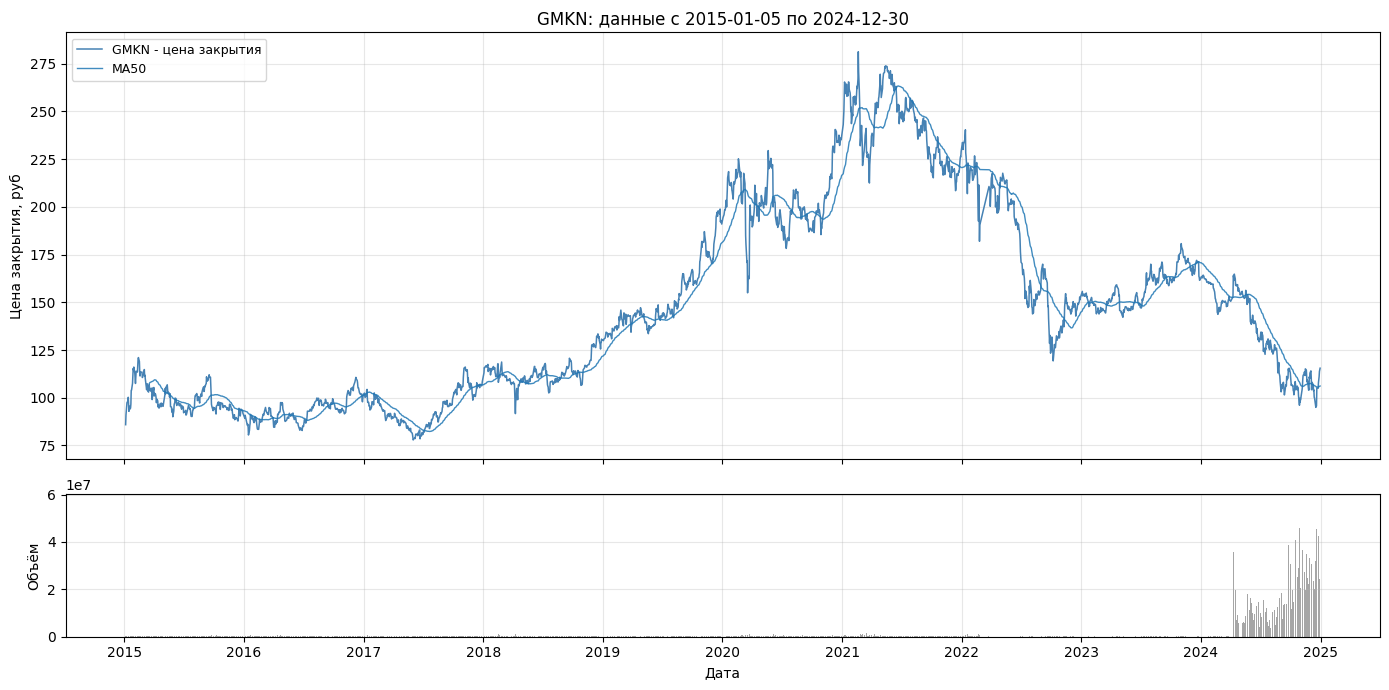

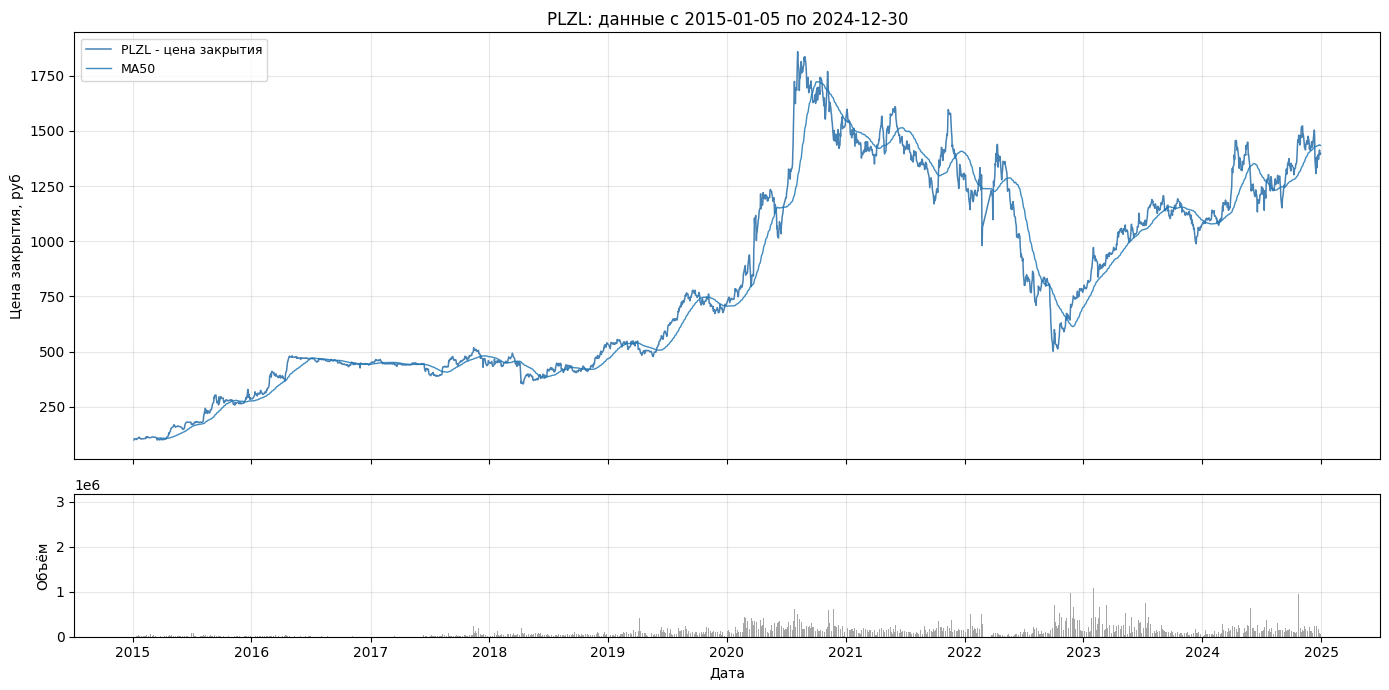

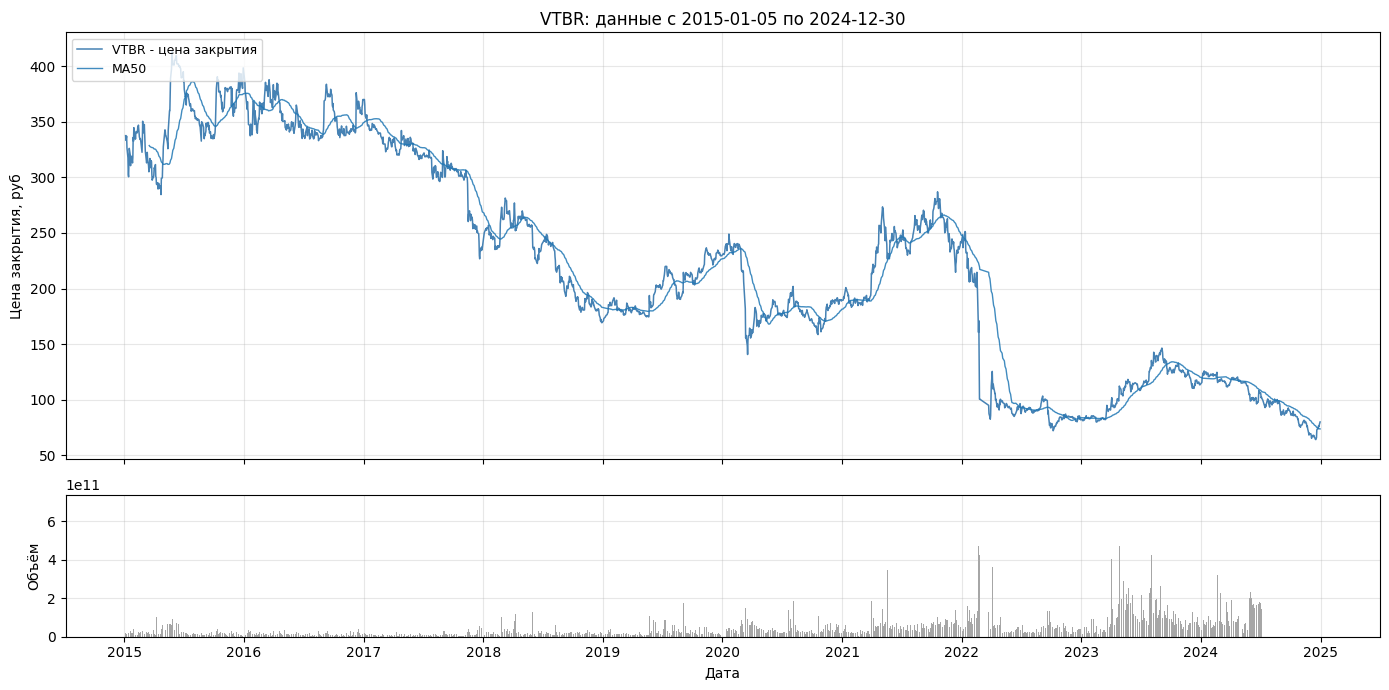

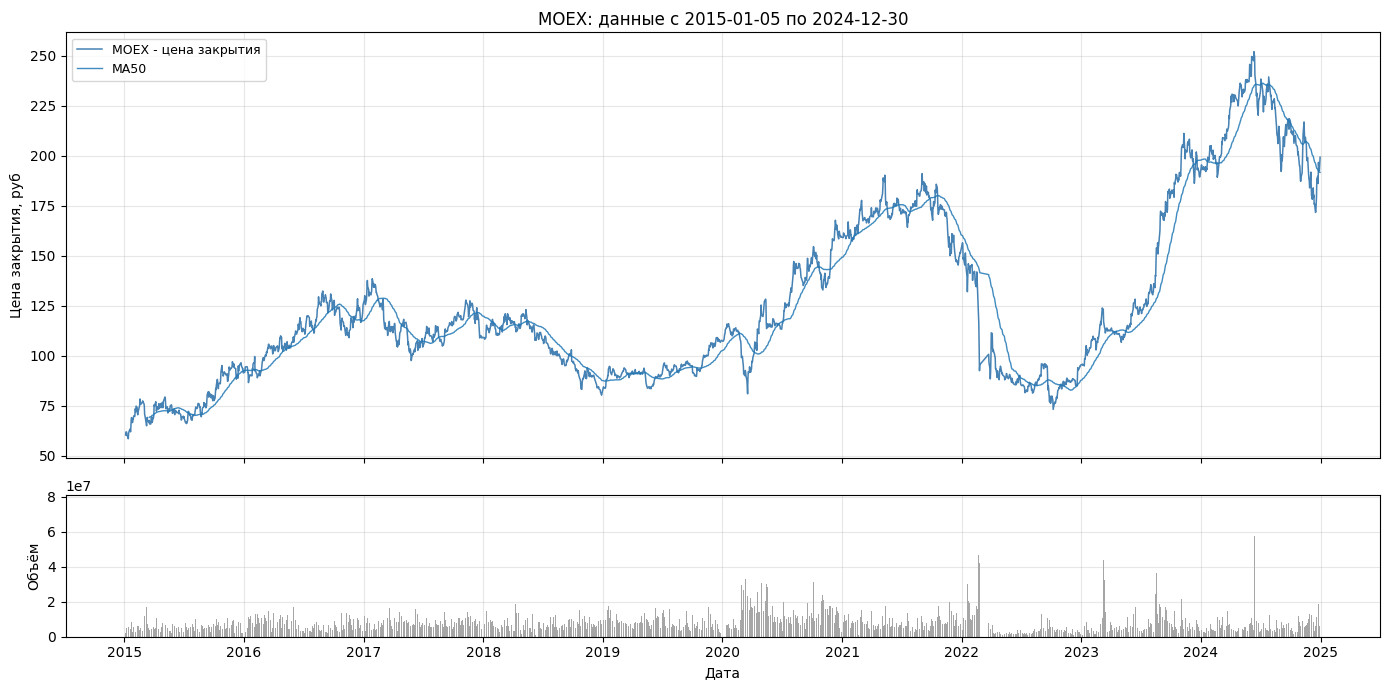

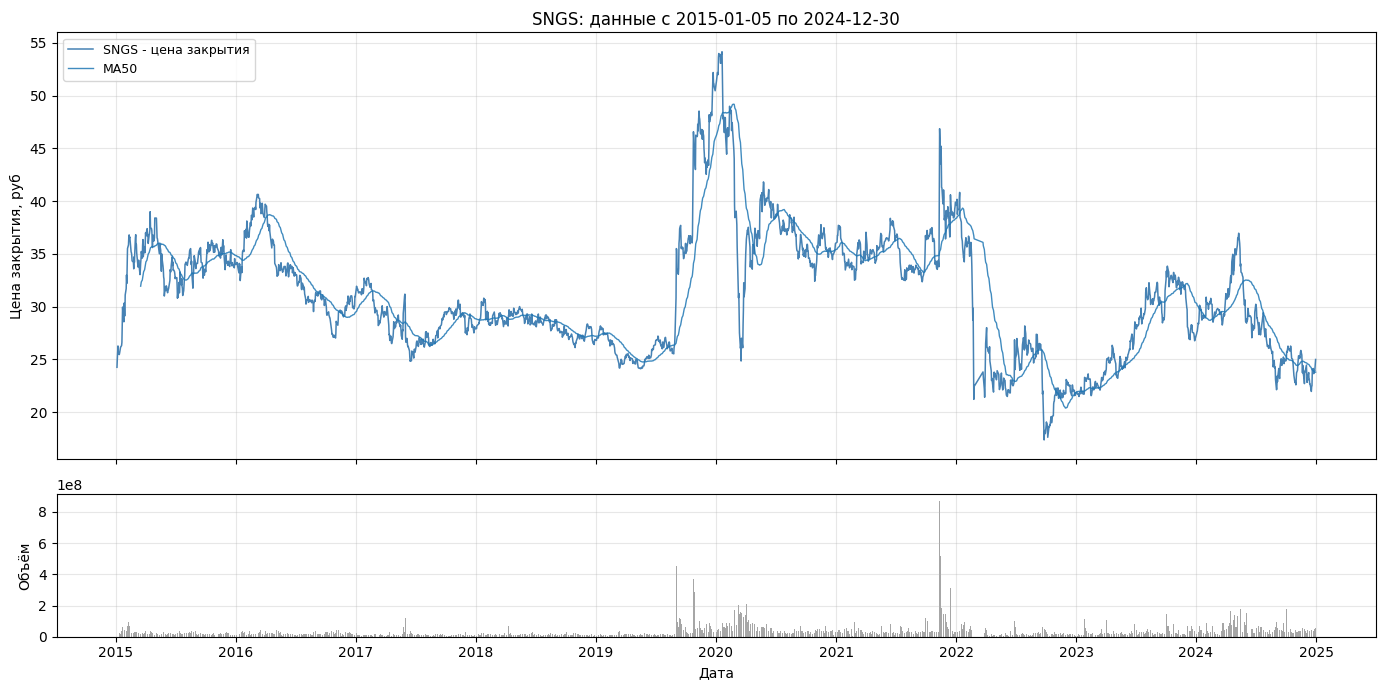

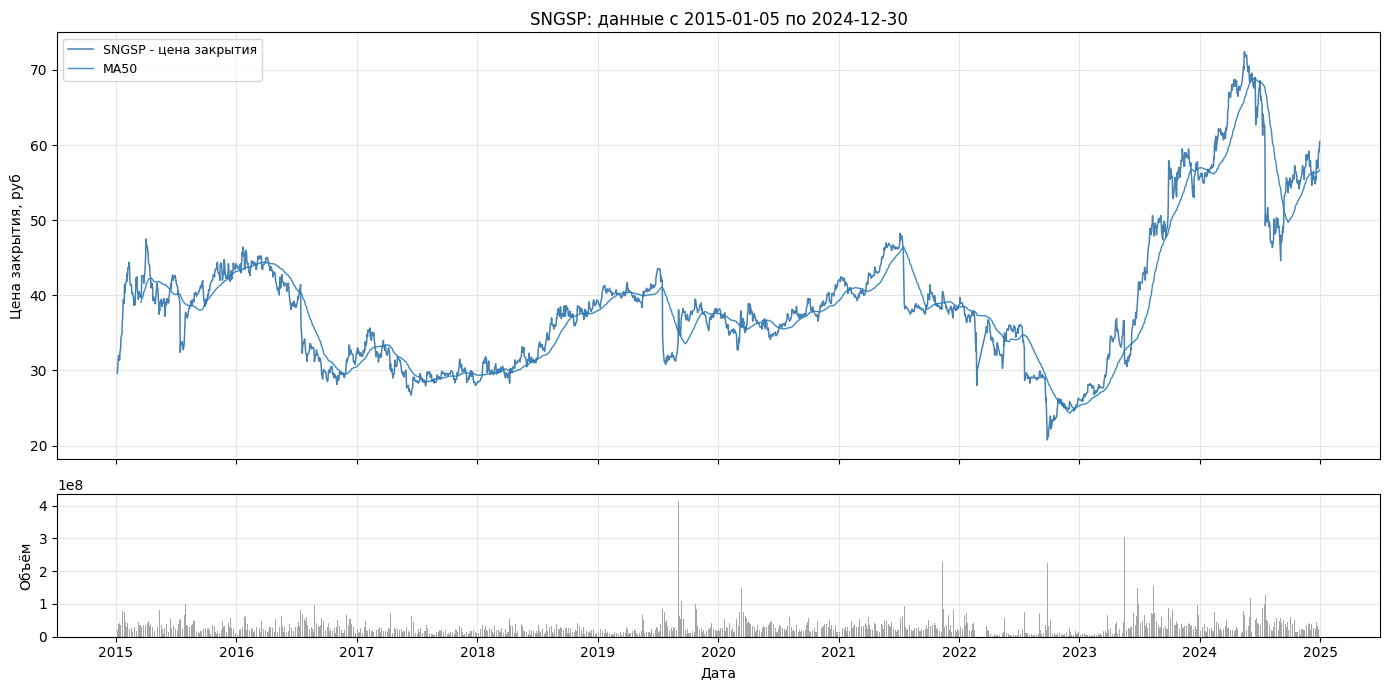

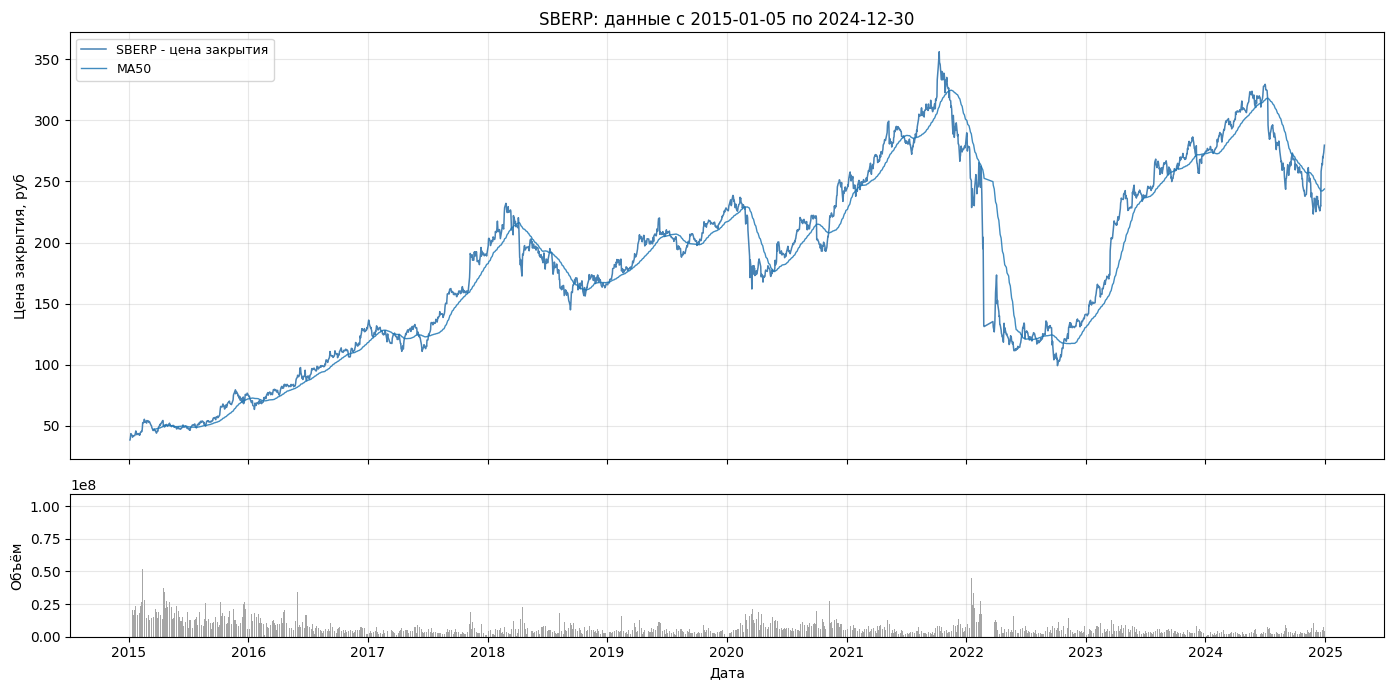

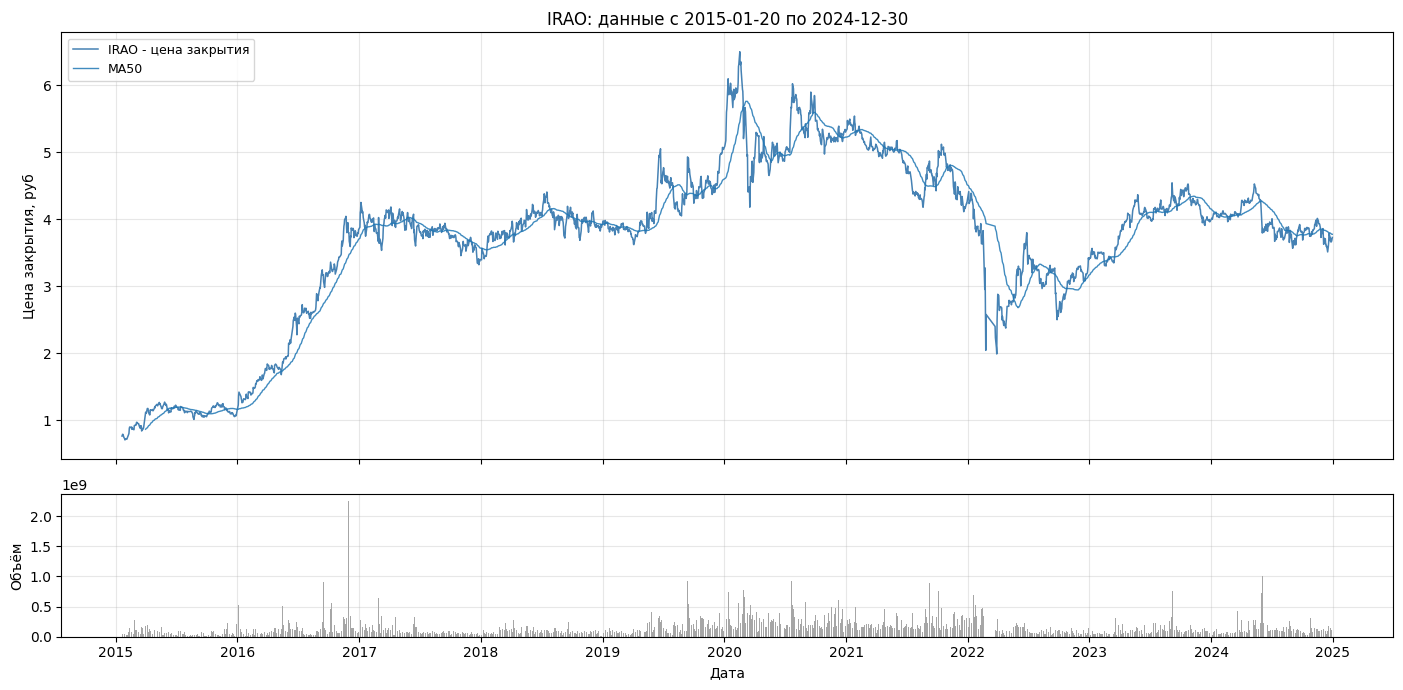

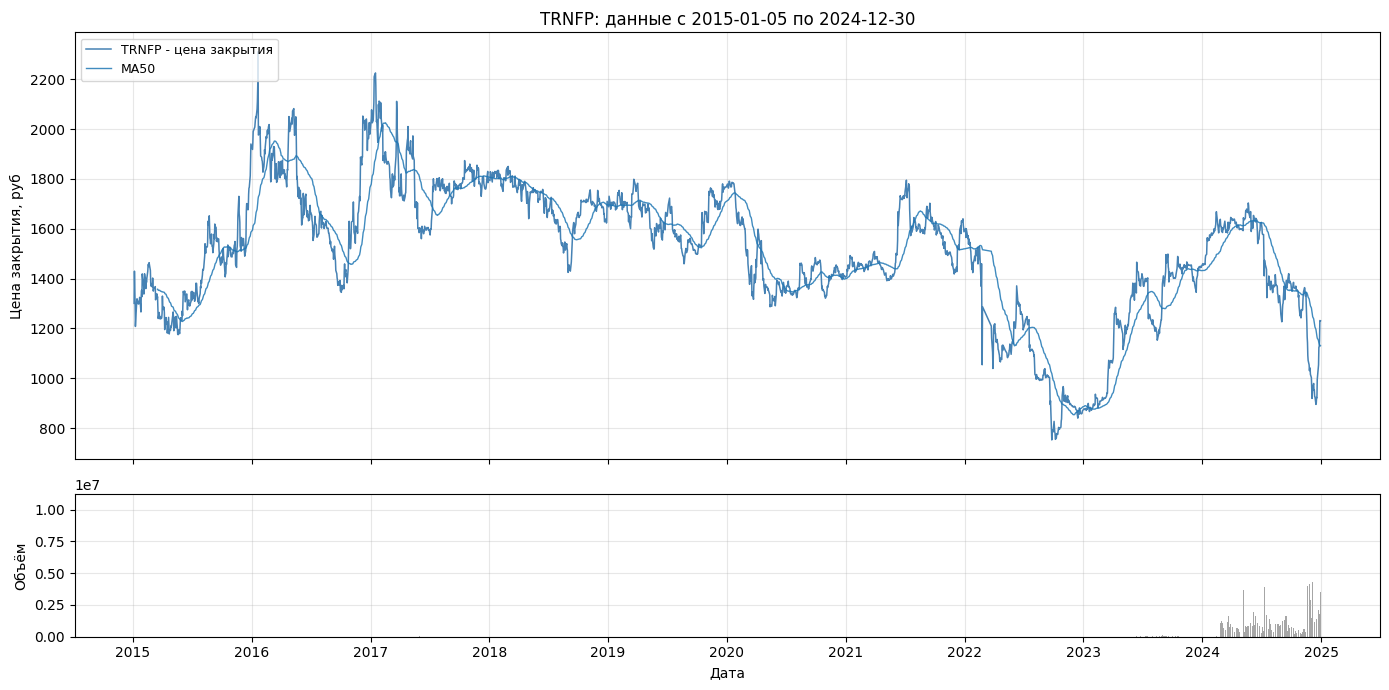

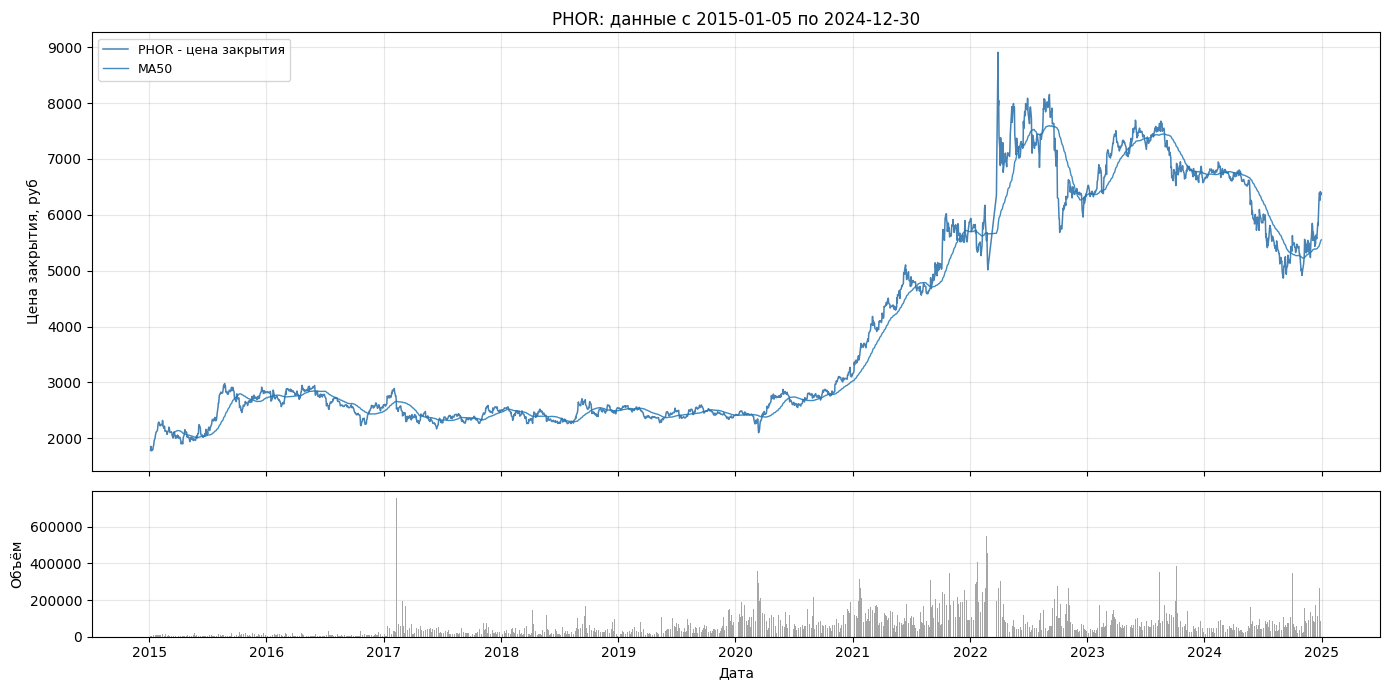

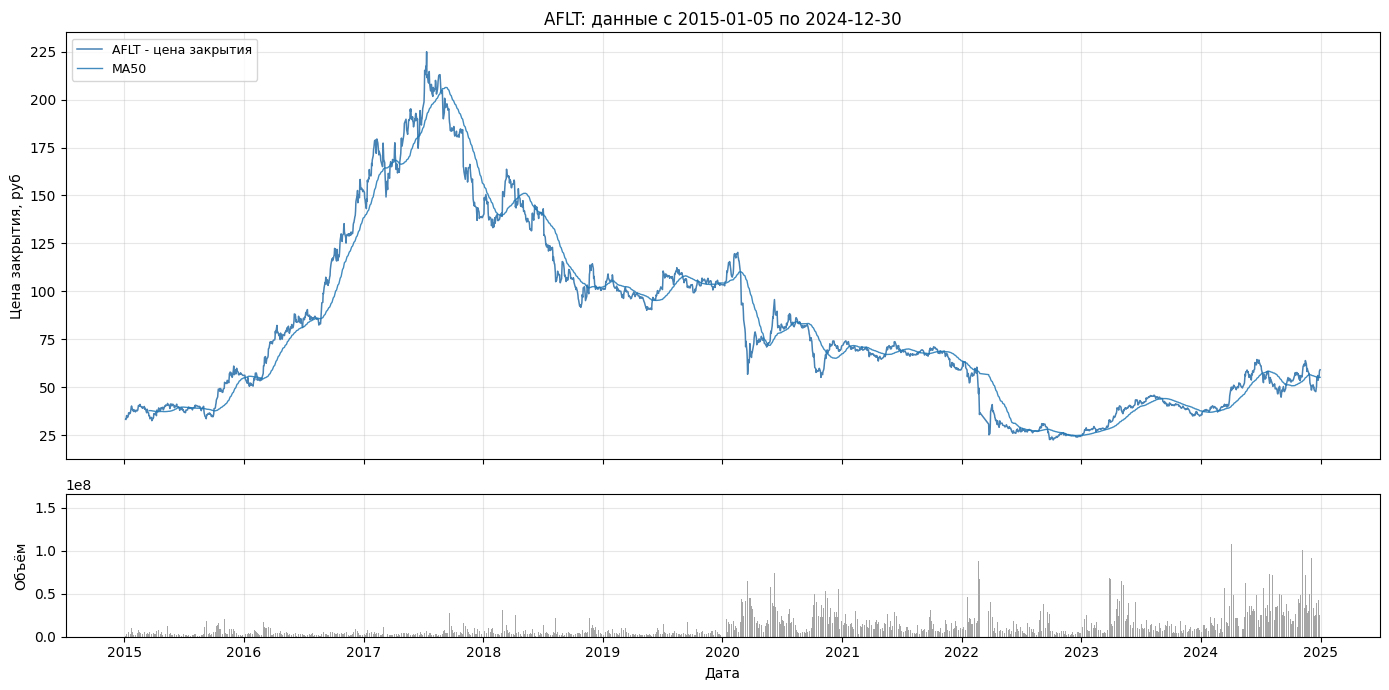

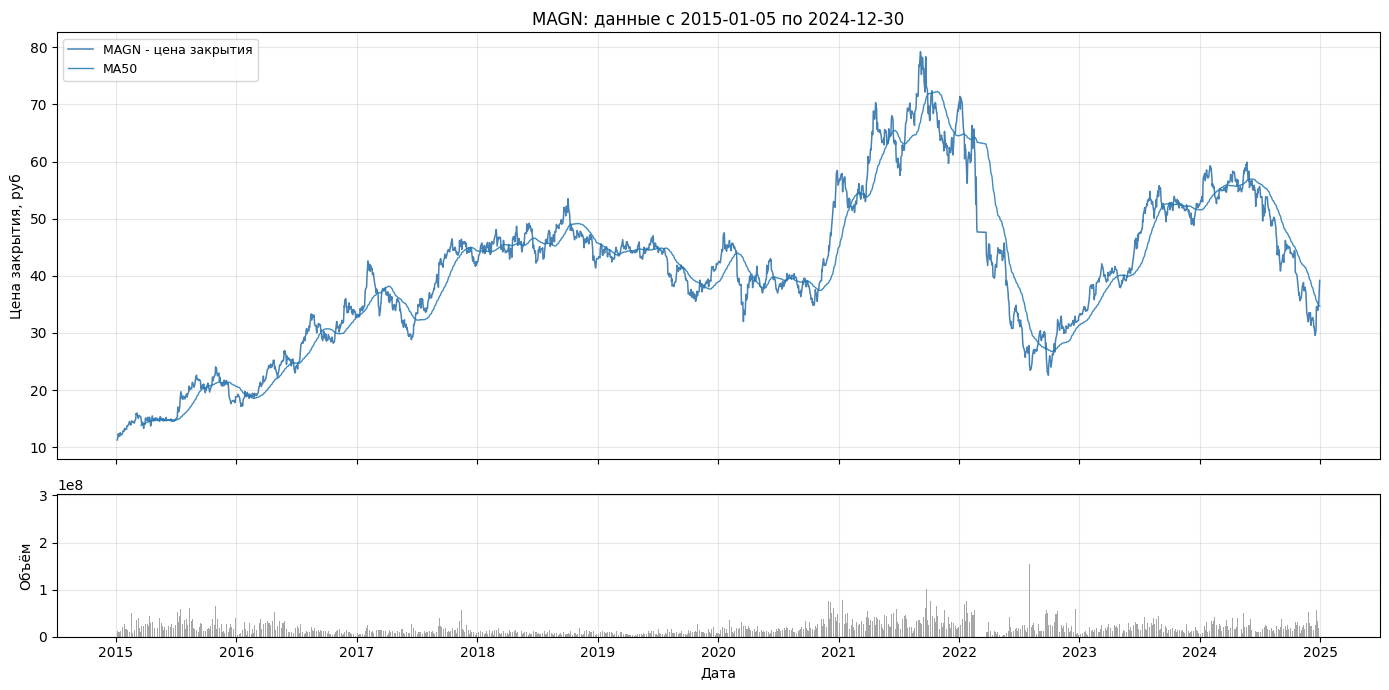

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

def make_plot(ticker: str, close: pd.DataFrame, volume: pd.DataFrame = None,
                  start=None, end=None, maw=(20, 50), save_dir=None):
  if ticker not in close.columns:
    print(f'{ticker}: нет данных')
    return

  s = close[ticker].dropna()
  # отбираем дни
  if start is not None:
    s = s[s.index >= pd.Timestamp(start)]
  if end is not None:
    s = s[s.index <= pd.Timestamp(end)]

  if s.empty:
    print(f'{ticker}: нет данных в указанном периоде')
    return

  # в зависимости от того, хотим отображать объём или нет
  if volume is not None and ticker in volume.columns:
    fig, (ax1, ax2) = plt.subplots(
        nrows=2, ncols=1, figsize=(14, 7), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )
  else:
    fig, ax1 = plt.subplots(figsize=(14, 6))
    ax2 = None

  ax1.plot(s.index, s.values, color='steelblue',
           linewidth=1.1, label=f'{ticker} - цена закрытия')

  # скользящие средние
  if maw:
    for w in maw:
      ma = s.rolling(w).mean()
      ax1.plot(ma.index, ma.values, linewidth=1, alpha=0.85, label=f'MA{w}')

  ax1.set_title(f'{ticker}: данные с {s.index.min().date()} по {s.index.max().date()}')
  ax1.set_ylabel('Цена закрытия, руб')
  ax1.grid(True, alpha=0.3)
  ax1.legend(loc='upper left', fontsize=9)

  if ax2 is not None:
    v = volume[ticker].reindex(s.index).fillna(0)
    ax2.bar(v.index, v.values, color='gray', width=1, alpha=0.7)
    ax2.set_ylabel('Объём')
    ax2.set_xlabel('Дата')
    ax2.grid(alpha=0.3)
  else:
    ax1.set_xlabel('Дата')

  last_ax = ax2 if ax2 is not None else ax1
  last_ax.xaxis.set_major_locator(mdates.YearLocator())
  last_ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

  plt.tight_layout()

  if save_dir:
      os.makedirs(save_dir, exist_ok=True)
      fname = os.path.join(save_dir, f'{ticker}_close.png')
      fig.savefig(fname, dpi=140, bbox_inches='tight')
      plt.close(fig)
      print(f'Цены закрытия для {ticker} сохранены в {fname}')
  else:
      plt.show()

path = 'data/raw/prices_moex_stable.parquet'

if not os.path.exists(path):
  raise FileNotFoundError(
      f'Не удалось загрузить файл {path}'
  )

combined = pd.read_parquet(path)
close = combined.xs('close', axis=1, level='field')
volume = combined.xs('volume', axis=1, level='field')

tickers = close.columns.tolist()
print(f'Тикеры: {tickers}')

folder = 'data/charts/close'  # для запуска в IDE и сохранения

for t in tickers:
  make_plot(t, close, volume, maw=(50,))


Из этих многочисленных графиков наиболее интересный эффект - обвал в начале 2022 года и резкий рост объёма торгов. Это, кстати, и есть прямое проявление новостного фона, которое было бы неплохо интегрировать в стратегию прогнозирования с помощью нейронных сетей. Например, можно анализировать как положительность/отрицательность новости, так и степень её влияния на рынок. В целом, простора для размышлений здесь много, но пока попробуем адаптировать анализ с целью дальнейшего обучения моделей на основе технических данных. Далее в последующих блокнотах мы реализуем ряд признаков на основе наших временных рядов, что будет иметь принципиальное значение в дальнейшем.

Среди используемых признаков будут: моментум-признаки (доходность за 1, 5, 10, 20 дней; кросс-секицонные доходности, то есть доходности каждой бумаги относительно среднего по рынку за выбранный период, нормированный на стандартное отклонение по всем бумагам - 1, 5, 20 дней), ревёрсал-признаки (разность между ценой закрытия и наименьшей ценой, делённая на разность наибольшей и наименьшей - если цена закрытия близка к наивысшей, то, как правило, на следующий день будет откат; разница между ценой закрытия и скользящим средним за 20 дней, нормированная на бегущее стандартное отклонение за 20 дней - бумаги, идущие далеко от ma20, как правило, возвращаются обратно), волатильность/риск (реализованная волатильность за 20 дней - бегущее стандартное отклонение логарифмических доходностей за 20 дней; волатильность с учётом гэпов - сглаживание Уайлдера, рассчитанное на гэпах, за 14 дней, нормированное на цену закрытия (для устранения влияния цены), - для улавливания внутридневных волатильностей;  кросс-секционный z-score волатильности - аналогично доходности, - вясняем, насколько волатильность отличается от среднего, будет нужно для расчёта IC; отношения короткой и длинной волатильностей (за 5 и 20 дней) - ловим начало периодов волатильности (кластеризация волатильностей); бета к рынку - отношение скользящей ковариации логарифмических доходностей за 20 дней с тем же показателем для рынка к скользящей дисперсии рыночной логарифмической доходности за тот же период; корреляция с рынком - скользящая ковариация логарифмических доходностей за 20 дней с аналогичным показателем для рынка, нормированный на скользящие стандартные отклонения доходностей и рынка за тот же период), осцилляторы (RSI(14) - доходности + сглаживание Уайлдера для придания большего веса последним дням -> relative strength -> RSI - перекупленность/перепроданность; кросс-секционный RSI(14)), объём (OBV MA20 - разность объёма с бегущим средним объёмом за 20 дней, нормированная на стандартное отклонение за 20 дней в объёмах; кросс-секционный volume_z, - отражают, насколько сильный сигнал). Все эти признаки реализованы в программе ниже.

In [3]:
import numpy as np

# вспомогательные функции
# вернуть нужное поле для всех тикеров
def _wide(prices, field):
  return prices.xs(field, level=1, axis=1)

# RSI со сглаживанием Уайлдера
def _wilder_rsi(close, n=14):
  delta = close.diff()
  gain = delta.clip(lower=0)
  loss = -delta.clip(upper=0)
  ag = gain.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
  al = loss.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
  rs = ag / al
  RSI = 100 - 100 / (1 + rs)

  return RSI

# нормированные величины
def _cs_zscore(df):
  mu = df.mean(axis=1)
  std = df.std(axis=1)
  return df.sub(mu, axis=0).div(std, axis=0)

# ранги
def _cs_rank(df):
  return df.rank(axis=1, pct=True) - 0.5

# безопасное деление
def _save_div(a, b):
  return a / b.replace(0, np.nan)

# кросс-секционные
def add_cross_sectional_features(tech_features):
  cs = {}
  skip = {'obv'}
  for name, df in tech_features.items():
    if name in skip:
      continue
    cs[f'cs_{name}_z'] = _cs_zscore(df)
    cs[f'cs_{name}_rank'] = _cs_rank(df)

  return cs


# признаки
def add_technical_features(prices):
  # извлекаем признаки
  close = _wide(prices, 'close')
  open_ = _wide(prices, 'open')
  high = _wide(prices, 'high')
  low = _wide(prices, 'low')
  volume = _wide(prices, 'volume')

  f = {}

  # доходности
  for i in [1, 5, 10, 20]:
    f[f'ret_{i}d'] = close.pct_change(i, fill_method=None)

  # логарифмические доходности
  log_ret = np.log(close / close.shift(1))
  f['log_ret_1d'] = log_ret

  # волатильности
  for i in [5, 20]:
    f[f'vol_{i}d'] = log_ret.rolling(i, min_periods=i).std()

  # отношение волатильностей
  f['vol_ratio_5_20'] = _save_div(f['vol_5d'], f['vol_20d'])

  # RSI14
  f['rsi_14'] = _wilder_rsi(close, 14)

  # ATR
  tr = pd.concat([
      high - low,
      (high - close.shift(1)).abs(),
      (low - close.shift(1)).abs()
  ]).groupby(level=0).max()
  f['atr_14'] = tr.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
  f['atr_norm'] = _save_div(f['atr_14'], close)

  # close position
  rng = high - low
  f['close_position'] = _save_div(close - low, rng)

  ma20 = close.rolling(20, min_periods=20).mean()
  std20 = close.rolling(20, min_periods=20).std()
  f['boll_pos'] = _save_div(close - ma20, 2 * std20)

  # объёмы
  vol20ma = volume.rolling(20, min_periods=20).mean()
  vol20std = volume.rolling(20, min_periods=20).std()
  f['volume_z'] = _save_div(volume - vol20ma, vol20std)

  # OBV
  sign = np.sign(close.diff())
  obv = (sign * volume).fillna(0).cumsum()
  f['obv_z'] = _save_div(obv - obv.rolling(20).mean(), obv.rolling(20).std())

  return f

# рыночные признаки
def add_market_features(prices):
  close = _wide(prices, 'close')
  log_ret = np.log(close / close.shift(1))

  mkt_ret = log_ret.mean(axis=1)

  f = {}

  cov = log_ret.rolling(20, min_periods=20).cov(mkt_ret)
  var = log_ret.rolling(20, min_periods=20).var()
  f['beta_20d'] = cov.div(var, axis=0)
  f['corr_20d'] = log_ret.rolling(20, min_periods=20).corr(mkt_ret)

  return f


# строим признаки
def add_features(prices):
  tech = add_technical_features(prices)
  cs = add_cross_sectional_features(tech)
  mkt = add_market_features(prices)

  all_feats = {**tech, **cs, **mkt}

  tickers = prices.columns.get_level_values(0).unique()
  out = {}
  for t in tickers:
    df_t = pd.DataFrame({name: f[t] for name, f in all_feats.items()})
    out[t] = df_t
  result = pd.concat(out, axis=1)
  result.columns.names = ['ticker', 'feature']

  return result


prices = pd.read_parquet('data/raw/prices_moex_stable.parquet')
features = add_features(prices)

print(features.shape)
print(features.head(25))



(2509, 940)
ticker          SBER                                                     \
feature       ret_1d    ret_5d   ret_10d   ret_20d log_ret_1d    vol_5d   
datetime                                                                  
2015-01-05       NaN       NaN       NaN       NaN        NaN       NaN   
2015-01-06  0.033883       NaN       NaN       NaN   0.033322       NaN   
2015-01-08  0.127316       NaN       NaN       NaN   0.119840       NaN   
2015-01-09 -0.039574       NaN       NaN       NaN  -0.040378       NaN   
2015-01-12 -0.003170       NaN       NaN       NaN  -0.003175       NaN   
2015-01-13 -0.041176  0.069895       NaN       NaN  -0.042048  0.067022   
2015-01-14 -0.004311  0.030371       NaN       NaN  -0.004320  0.066351   
2015-01-15  0.029142 -0.059361       NaN       NaN   0.028726  0.029595   
2015-01-16  0.003074 -0.017591       NaN       NaN   0.003070  0.025340   
2015-01-19 -0.003065 -0.017488       NaN       NaN  -0.003070  0.025340   
2015-01-20 -0